In [2]:

# ===== 1. Load the data =====
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252",
                 parse_dates=["Order Date", "Ship Date"])

print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# ===== 2. Check data quality =====
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df.info()

Missing values: 0
Duplicate rows: 0
Date range: 2014-01-03 to 2017-12-30
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category  

In [4]:
# ===== 3. Key KPIs =====
sales = df["Sales"].sum()
profit = df["Profit"].sum()
print(f"Total Sales:  ${sales:,.0f}")
print(f"Total Profit: ${profit:,.0f}")
print(f"Margin:       {profit/sales:.1%}")
print(f"Orders:       {df['Order ID'].nunique():,}")
print(f"Customers:    {df['Customer ID'].nunique():,}")

Total Sales:  $2,297,201
Total Profit: $286,397
Margin:       12.5%
Orders:       5,009
Customers:    793


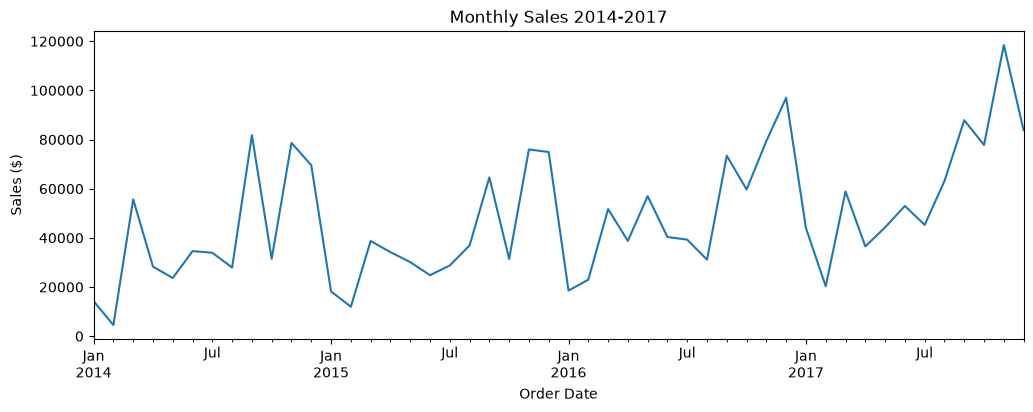

In [5]:
# ===== 4. Monthly sales trend =====
monthly = df.set_index("Order Date").resample("ME")["Sales"].sum()
monthly.plot(figsize=(12,4), title="Monthly Sales 2014-2017")
plt.ylabel("Sales ($)")
plt.show()

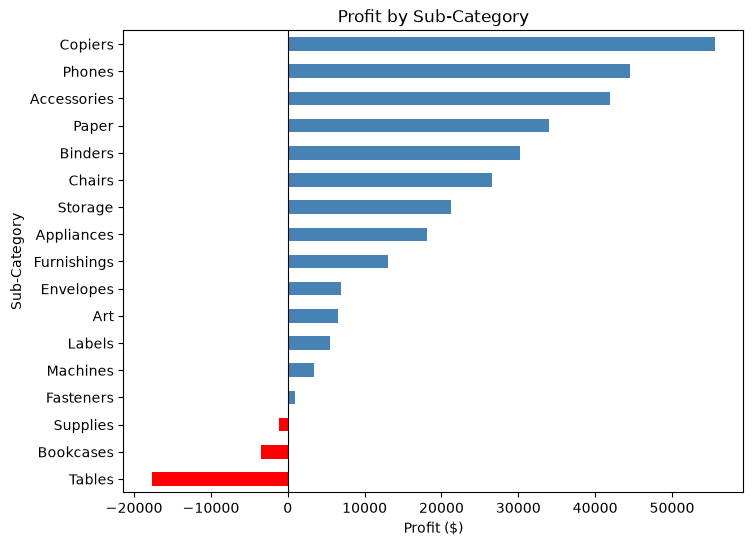

In [6]:
# ===== 5. Profit by sub-category =====
sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
colors = ["red" if x < 0 else "steelblue" for x in sub]
sub.plot(kind="barh", figsize=(8,6), color=colors, title="Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

Correlation: -0.22


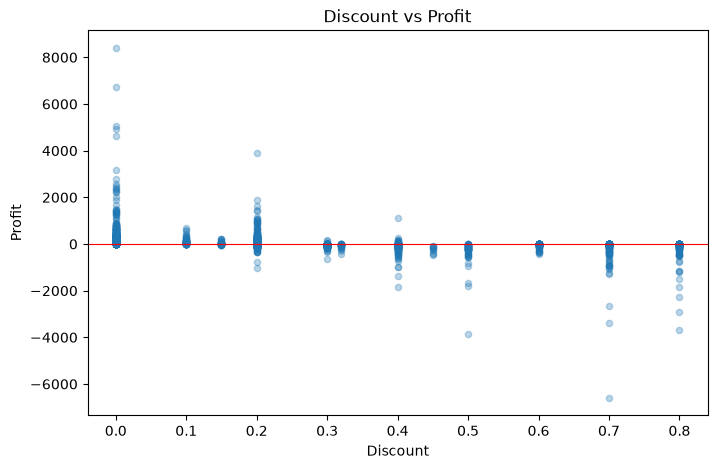

In [7]:
# ===== 7. Discount vs profit =====
print("Correlation:", round(df["Discount"].corr(df["Profit"]), 2))

df.plot(kind="scatter", x="Discount", y="Profit", alpha=0.3,
        figsize=(8,5), title="Discount vs Profit")
plt.axhline(0, color="red", linewidth=0.8)
plt.show()

Discount
No discount     66.9
1-20%           26.5
21-40%         -77.9
Over 40%      -106.7
Name: Profit, dtype: float64


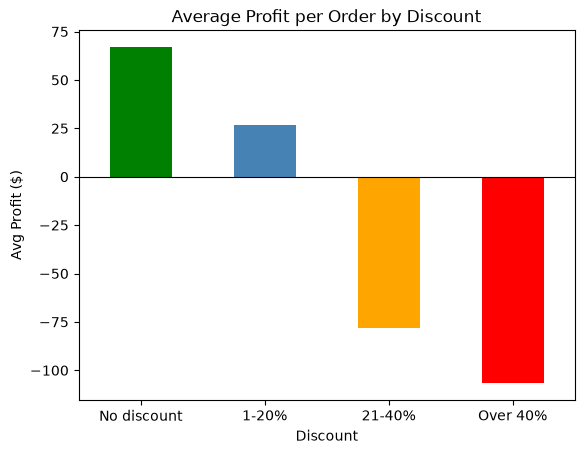

In [8]:
# ===== 8. Average profit by discount band =====
bands = pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1],
               labels=["No discount", "1-20%", "21-40%", "Over 40%"])
result = df.groupby(bands, observed=True)["Profit"].mean().round(1)
print(result)

result.plot(kind="bar", color=["green","steelblue","orange","red"],
            title="Average Profit per Order by Discount", rot=0)
plt.ylabel("Avg Profit ($)")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

In [9]:
# ===== 9. Average discount vs margin by region and category =====
for col in ["Region", "Category"]:
    g = df.groupby(col).agg(avg_discount=("Discount", "mean"),
                            sales=("Sales", "sum"), profit=("Profit", "sum"))
    g["margin"] = g["profit"] / g["sales"]
    print(g[["avg_discount", "margin"]].round(3), "\n")

         avg_discount  margin
Region                       
Central         0.240   0.079
East            0.145   0.135
South           0.147   0.119
West            0.109   0.149 

                 avg_discount  margin
Category                             
Furniture               0.174   0.025
Office Supplies         0.157   0.170
Technology              0.132   0.174 



## Conclusions
1. Sales grew 51% from 2014 to 2017, with peaks every Sept–Dec.
2. Tables, Bookcases and Supplies lose money overall.
3. Discounts above 20% turn the average order into a loss (-$78 to -$107 per order).
4. Central gives the highest average discount (24%) and has the lowest margin (7.9%).
5. Furniture has the highest discount rate (17%) and only a 2.5% margin.

Recommendation: cap discounts at 20%, review pricing on Tables and Bookcases, and investigate the cost of Supplies.